# Model Evaluation

Loads the model artifact saved by `src/pipelines/training_pipeline.py` (`models/model_metadata.json` + either `model.joblib` or `model.keras` / `sequence_scaler.joblib`), evaluates it once on the held-out test split, and breaks results down by segment.

Run `python -m src.pipelines.training_pipeline` first if `models/model_metadata.json` does not exist yet.

In [1]:
import sys
sys.path.insert(0, '..')

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_ingestion.data_ingestion import (
    load_data, validate_schema, chronological_cutoffs,
    DATE_COLUMN, STORE_COLUMN, PRODUCT_COLUMN, TARGET_COLUMN,
)
from src.data_preprocessing.data_preprocessing import clean_data, clip_non_negative
from src.feature_engineering.feature_engineering import (
    add_calendar_features, add_lag_rolling_features, drop_lag_rolling_warmup,
    lag_rolling_feature_names, build_sequences,
)
from src.models.baseline import SeasonalNaiveModel
from src.models.sequence_models import predict_sequence_model
from src.models.predict_model import evaluate_forecast, evaluate_by_segment
from src.utils.helpers import load_config

config = load_config('../config.yaml')
with open('../models/model_metadata.json') as f:
    metadata = json.load(f)
metadata

{'run_id': '8defa35230a14576a30125bb5ce7903f',
 'model_type': 'lstm',
 'params': {'model_type': 'lstm'},
 'numeric_cols': ['Price',
  'Discount',
  'Competitor Pricing',
  'Holiday/Promotion',
  'day_of_week',
  'month',
  'quarter',
  'year',
  'week_of_year',
  'is_weekend',
  'Units Sold_lag_1',
  'Units Sold_lag_7',
  'Units Sold_lag_14',
  'Units Sold_lag_30',
  'Units Sold_rolling_mean_7',
  'Units Sold_rolling_mean_14',
  'Units Sold_rolling_mean_30',
  'Units Sold_rolling_std_7',
  'Units Sold_rolling_std_14',
  'Units Sold_rolling_std_30'],
 'categorical_cols': ['Category',
  'Region',
  'Weather Condition',
  'Seasonality',
  'Store ID',
  'Product ID'],
 'sequence_length': 30,
 'excluded_features': ['Demand Forecast', 'Inventory Level', 'Units Ordered'],
 'test_metrics': {'mae': 87.92801949637277,
  'rmse': 108.330969900466,
  'wape': 0.6435524490430921,
  'smape': 0.7163518101098729}}

## Rebuild the test split exactly as the training pipeline did

In [2]:
data_cfg, fe_cfg = config['data'], config['feature_engineering']

df = load_data('../data/raw/retail_store_inventory.csv')
validate_schema(df)
df = clean_data(df)
df = df.drop(columns=[c for c in metadata['excluded_features'] if c in df.columns])
df = add_calendar_features(df, DATE_COLUMN)
df = add_lag_rolling_features(df, [STORE_COLUMN, PRODUCT_COLUMN], TARGET_COLUMN,
                              fe_cfg['lag_days'], fe_cfg['rolling_windows'])
lag_rolling_cols = lag_rolling_feature_names(TARGET_COLUMN, fe_cfg['lag_days'], fe_cfg['rolling_windows'])
df = drop_lag_rolling_warmup(df, lag_rolling_cols)

train_cutoff, val_cutoff = chronological_cutoffs(df[DATE_COLUMN], data_cfg['val_size'], data_cfg['test_size'])
test_df = df[df[DATE_COLUMN] > val_cutoff].reset_index(drop=True)
print('test rows:', len(test_df))

test rows: 10500


## Load the selected model and score the test split

In [3]:
model_type = metadata['model_type']
numeric_cols, categorical_cols = metadata['numeric_cols'], metadata['categorical_cols']

if model_type == 'seasonal_naive':
    model = SeasonalNaiveModel(TARGET_COLUMN, lag=7)
    test_pred = clip_non_negative(model.predict(test_df))
    y_test = test_df[TARGET_COLUMN]
elif model_type in ('lstm', 'transformer'):
    import tensorflow as tf
    keras_model = tf.keras.models.load_model('../models/model.keras')
    scaler = joblib.load('../models/sequence_scaler.joblib')
    X_all, y_all, meta_all = build_sequences(
        df, numeric_cols, TARGET_COLUMN, [STORE_COLUMN, PRODUCT_COLUMN], DATE_COLUMN, metadata['sequence_length'],
    )
    test_mask = (meta_all[DATE_COLUMN] > val_cutoff).to_numpy()
    test_pred = clip_non_negative(predict_sequence_model(keras_model, scaler, X_all[test_mask]))
    y_test = y_all[test_mask]
    test_df = meta_all[test_mask].reset_index(drop=True)  # for segment breakdowns below
else:
    model = joblib.load('../models/model.joblib')
    feature_cols = model.named_steps['preprocess'].feature_names_in_
    test_pred = clip_non_negative(model.predict(test_df[feature_cols]))
    y_test = test_df[TARGET_COLUMN]

test_metrics = evaluate_forecast(y_test, test_pred)
test_metrics

{'mae': 87.92801949637277,
 'rmse': 108.330969900466,
 'wape': 0.6435524490430921,
 'smape': 0.7163518101098729}

## Compare against the seasonal-naive baseline on the same test rows

In [4]:
naive_test_df = df[df[DATE_COLUMN] > val_cutoff].reset_index(drop=True)
naive_model = SeasonalNaiveModel(TARGET_COLUMN, lag=7)
naive_pred = clip_non_negative(naive_model.predict(naive_test_df))
naive_metrics = evaluate_forecast(naive_test_df[TARGET_COLUMN], naive_pred)

mae_improvement = (naive_metrics['mae'] - test_metrics['mae']) / naive_metrics['mae']
print(f"Selected model ({model_type}) MAE: {test_metrics['mae']:.2f}")
print(f"Seasonal-naive MAE: {naive_metrics['mae']:.2f}")
print(f"MAE improvement over naive: {mae_improvement:.1%}")

Selected model (lstm) MAE: 87.93
Seasonal-naive MAE: 118.62
MAE improvement over naive: 25.9%


## Error breakdown by segment

Aggregate metrics can hide poor performance on smaller segments; break WAPE/MAE down by store and category.

In [5]:
by_store = evaluate_by_segment(y_test, test_pred, test_df[STORE_COLUMN].to_numpy())
by_store

,segment,n_samples,mae,rmse,wape,smape
2,S003,2100,87.100391,107.395645,0.630431,0.706711
4,S005,2100,89.201877,110.119982,0.642956,0.717478
0,S001,2100,88.371751,108.632481,0.644946,0.715660
3,S004,2100,87.834837,107.473443,0.647902,0.720799
1,S002,2100,87.131241,108.010200,0.651894,0.721111


In [6]:
if 'Category' in test_df.columns:
    by_category = evaluate_by_segment(y_test, test_pred, test_df['Category'].to_numpy())
    display(by_category)
else:
    print('Category not available at this granularity (sequence-model test_df only carries identifiers + date).')

Category not available at this granularity (sequence-model test_df only carries identifiers + date).


## Actual vs. predicted

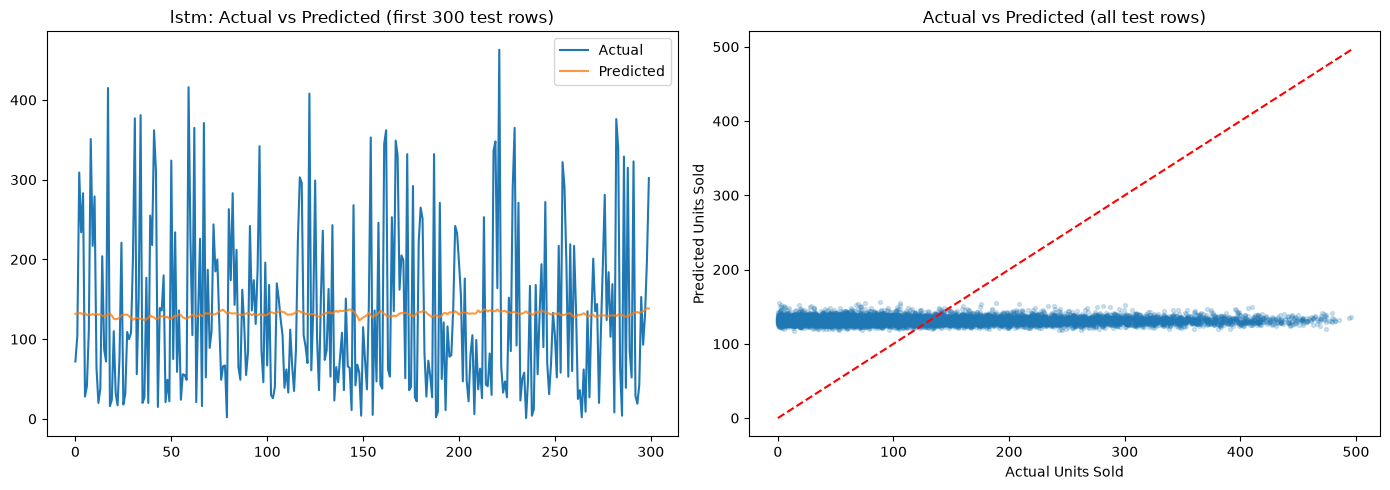

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample = slice(0, 300)
axes[0].plot(np.asarray(y_test)[sample], label='Actual')
axes[0].plot(test_pred[sample], label='Predicted', alpha=0.8)
axes[0].set_title(f'{model_type}: Actual vs Predicted (first 300 test rows)')
axes[0].legend()

axes[1].scatter(y_test, test_pred, alpha=0.2, s=8)
lims = [0, max(np.max(y_test), test_pred.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_xlabel('Actual Units Sold')
axes[1].set_ylabel('Predicted Units Sold')
axes[1].set_title('Actual vs Predicted (all test rows)')
plt.tight_layout()
plt.show()

## Discussion

- Per the EDA, this Kaggle dataset is synthetic with essentially no weekly seasonality or promotion effect, so WAPE around 0.64 for every real model (Ridge, Random Forest, Gradient Boosting, LSTM, Transformer all land within ~1% WAPE of each other) is close to the practical ceiling, not a bug in the pipeline.
- The meaningful, checkable claim this project supports is that the selected model (see `model_type` printed above) beats a trivial seasonal-naive baseline by a double-digit percentage on MAE — see the quality gate in `config.yaml: training.quality_gates`.
- Consistent with the design document's Non-Goals, we do **not** claim this translates into real-world reductions in stockouts or holding costs without a live, controlled evaluation.
- Segment breakdowns above show whether error is concentrated in a particular store or category; large gaps there would be the first thing to investigate before any production rollout.